# ACTIVIDAD FUNDAMENTAL 6
## Ejercicio de Árbol de Decisión

<h3>INSTALACIÓN DE LAS LIBRERÍAS NECESARIAS</h3>
<p>Antes de comenzar, deberemos instalar las librerias necesarias para el funcionamiento de nuestro programa. Las cuales son las siguientes:</p>
<ul>
    <li><b>Pandas:</b> Para crear dataframes y tablas que nos sirvan para analizar y manejar los datos de forma sencilla</li>
    <li><b>Numpy:</b> Para realizar calculos y operaciones matemáticas matriciales en nuestro dataframes</li>
    <li><b>Matplotlib y Seaborn:</b> Para la representacion gráfica de nuestros datos y facilitar el análisis de estos.</li>
    <li><b>Scikit Learn:</b> Para la creacion de nuestro modelo de inteligencia artificial, en este caso un árbol de decisión</li>
</ul>

In [ ]:
pip install pandas numpy matplotlib scikit-learn seaborn

<h3>IMPORTAR LOS DATOS</h3>
<p>
    En esta primer parte del ejercicio nos encargamnos de <b>implementar la fuente de datos</b> de diabetes con el URL situado mas abajo.
</p>

<p>Asimismo, podemos apreciar como tambien importamos cada una de las librerias necesarias para la ejecución de nuestro programa.</p>

<p>
    Para implementar nuestra fuente de datos utilizamos la funcion de pandas <b>pd.read_csv()</b> en la que colocamos el link junto con los nombres de las columnas para asi obtener el dataframe con todos los datos
</p>

<p>Al finalizar, unicamente mostramos los primeros 5 datos utilizando la funcion <b>df.head()</b> y describimos todas sus caracteristicas utilizando la funcion <b>df.describe()</b></p>

In [2]:
# IMPORTAR FUENTE DE DATOS

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# URL pública del dataset de Diabetes
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("Primeras filas del dataset original:")
df.head()

Primeras filas del dataset original:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<h3>DESCRIBIR LOS DATOS</h3>
<p>
    Utilizando la funcion <b>describe()</b> mostramos conteos automaticos de nuestro dataset como por ejemplo los embarazos, glucosa, insulina, BMI (Indice de Masa Corporal), edad u otros. Aunque uno de los mas importantes es el <b>Outcome</b>, que contiene valores binarios de 0 y 1, sirviendonos para diferenciar a una persona con diabetes (1) de una sana (0).</b>
</p>
<p>
    Asimismo, utilizamos la función <b>info()</b> para observar el DType de nuestros datos para determinar que variables son numéricas o categóricas. Aunque en este conjunto no fue de mucha ayuda debido a que todos los datos eran numéricos, incluyendo a los que utilizaríamos para etiquetar.
</p>

In [3]:
df.describe()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


<h3>MOSTRAR DATOS SIN PROCESAR</h3>
<p>
    Antes de procesar los datos y limpiarlos para pasarlos por nuestro modelo, podemos mostrarlos utilizando matplotlib.
    Para ello seleccionaremos dos características principales: Glucosa (x) y BMI (y).
    Asimismo, filtramos los datos pertenecientes a a outcome 1 y 0 en ambas features seleccionadas y las mostramos con otro color (rojo, en este caso).
</p>

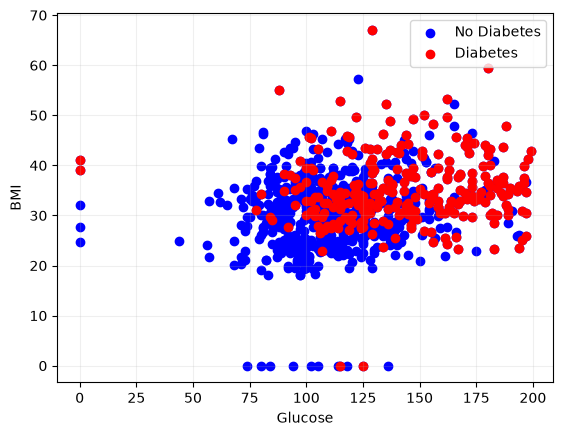

In [4]:
# MOSTRAR DATOS SIN PROCESAR

x = df['Glucose']
y = df['BMI']

x_diabetes = df[df['Outcome'] == 1]['Glucose']
y_diabetes = df[df['Outcome'] == 1]['BMI']

plt.scatter(x, y, c='blue', label = 'No Diabetes')
plt.scatter(x_diabetes, y_diabetes, c='red', label = 'Diabetes')

plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend()
plt.grid(visible=True, alpha=0.2)

<h3>LIMPIEZA DE DATOS</h3>

<h5>Filtrado de Valores Nulos o datos Faltantes</h5>
<p>
    Para la limpieza de los datos, seleccionamos primero las columnas que podrían sesgar la prediccion si los datos quedan en 0.
    Reemplazamos los ceros (valores imposibles) por valores nulos y posteriormente utilizamos <b>KNNImputer</b> para estimar los valores faltantes según los pacientes con características similares, evitando distorsionar la distribución de la insulina.
</p>

In [5]:
# Estas son las columnas cuyos valores no pueden ser cero (0)
columnasSesgadas = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[columnasSesgadas] = df[columnasSesgadas].replace(0, np.nan)

# Imputar valores nulos usando los 5 vecinos más cercanos para mantener la varianza natural
imputer = KNNImputer(n_neighbors=5)
features_imputar = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
df[features_imputar] = imputer.fit_transform(df[features_imputar])


<h5>Eliminación de Datos Duplicados</h5>
<p>
    Utilizamos la función <b>drop_duplicates()</b> reasignando directamente al dataframe (sin utilizar <b>inplace=True</b>) para evitar que el dataframe se sobreescriba como <i>None</i>.
</p>

In [6]:
df = df.drop_duplicates()

<h4>Filtro de 'Outliers' Utilizando el Rango Intercuartílico</h4>
<p>
    Posteriormente, calculamos el rango intercuartilico (IQR) para usarlo como filtro de los outliers en los datos basandonos en la insulina.
    Para obtenerlo restamos el 1er cuartil al 3ro y el resultado lo multiplicamos por 1.5.
    Despues, establecemos los limites superior e inferior usando la mediana como base e incrementandole el IQR calculado previamente.
</p>
<p>
    Al ya tener los outliers, filtramos el dataframe usandolos como base.
</p>

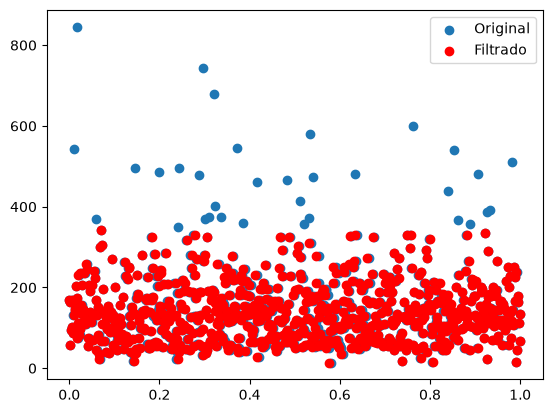

In [7]:
# Rango Intercuartilico (IQR)
Q1 = df['Insulin'].quantile(0.25)
Q3 = df['Insulin'].quantile(0.75)

IQR = Q3 - Q1

# Limites superior e inferior para outliers
limLower = Q1 - (1.5 * IQR)
limUpper = Q3 + (1.5 * IQR)

# Filtramos outliers
mask = (df['Insulin'] <= limUpper) & (df['Insulin'] >= limLower)

x = np.linspace(0, 1, df['Insulin'].size)
x2 = np.linspace(0, 1, df[mask]['Insulin'].size)

plt.scatter(x, df['Insulin'], label='Original')
plt.scatter(x2, df[mask]['Insulin'], c='Red', label='Filtrado')
plt.legend()

df = df[mask]

<h4>Resolviendo Imbalance de Clases</h4>
<p>
    Al utilizar el IQR para filtrar y eliminar gran cantidad de los datos exteriores, nos hemos quedado con una mayor cantidad de datos en personas sin diabetes que con diabetes. Para ello, calculamos automáticamente la diferencia entre ambas etiquetas y eliminamos el excedente utilizando una semilla fija (<b>random_state=42</b>) para tener la misma cantidad de datos y no sesgar nuestro modelo.
</p>

In [8]:
# Calculamos la diferencia exacta entre personas sin diabetes (0) y con diabetes (1)
conteo = df['Outcome'].value_counts()
diferencia = conteo[0] - conteo[1]

# Eliminamos la diferencia de forma reproducible
df = df.drop(df[df['Outcome'] == 0].sample(n=diferencia, random_state=42).index)

print("Conteo balanceado por clase:")
print(df['Outcome'].value_counts())

Conteo balanceado por clase:
Outcome
1    245
0    245
Name: count, dtype: int64


<h4>Muestra de Datos Filtrados</h4>

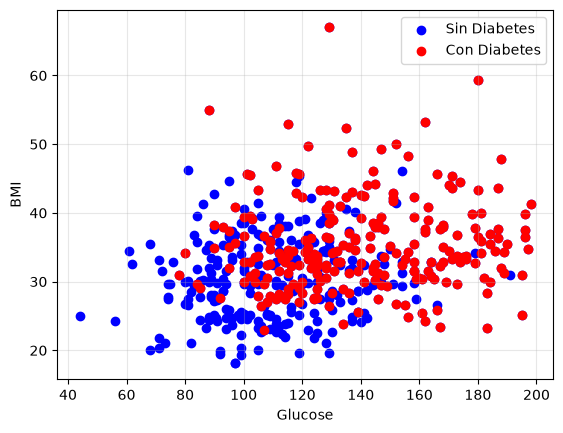

In [9]:
# Seleccionamos datos en X y Y
x = df['Glucose']
y = df['BMI']

# Seleccionamos datos de gente CON diabetes (Outcome = 1)
x_diabetes = df[df['Outcome'] == 1]['Glucose']
y_diabetes = df[df['Outcome'] == 1]['BMI']

# Mostramos ambos datos uno encima de otro usando scatter
plt.scatter(x, y, c='blue', label='Sin Diabetes')
plt.scatter(x_diabetes, y_diabetes, c='red', label='Con Diabetes')

plt.xlabel('Glucose')
plt.ylabel('BMI')

plt.legend()
plt.grid(visible=True, alpha=0.3)

<h4>Entrenamiento y Optimización del Árbol de Decisión</h4>
<p>
    En esta última sección, entrenamos el árbol de decisión utilizando los datos procesados.
    Para ello, primero partimos en dos DF diferentes los features y los targets para poder trabajar con ellos.
    Después dividimos esos datos en los de entrenamiento y de prueba utilizando la funcion <b>train_test_split()</b> con un 25% de prueba, una seed random de 42 y el parámetro <b>stratify=dfTargets</b> para conservar el balance de clases.
</p>
<p>
    Para incrementar la eficiencia en la predicción y evitar el sobreajuste (<i>overfitting</i>), configuramos el modelo limitando su profundidad máxima (<b>max_depth=4</b>) y el mínimo de muestras por hoja (<b>min_samples_leaf=5</b>). Posteriormente evaluamos su accuracy y generamos el <b>reporte de clasificación</b> utilizando una predicción generada con la parte de los datos separados para el test.
</p>
<p>Finalmente generamos el plot tree usando la funcion <b>plot_tree()</b>.</p>

Accuracy en entrenamiento: 0.78
Accuracy en prueba: 0.67

              precision    recall  f1-score   support

           0       0.87      0.42      0.57        62
           1       0.61      0.93      0.74        61

    accuracy                           0.67       123
   macro avg       0.74      0.68      0.65       123
weighted avg       0.74      0.67      0.65       123



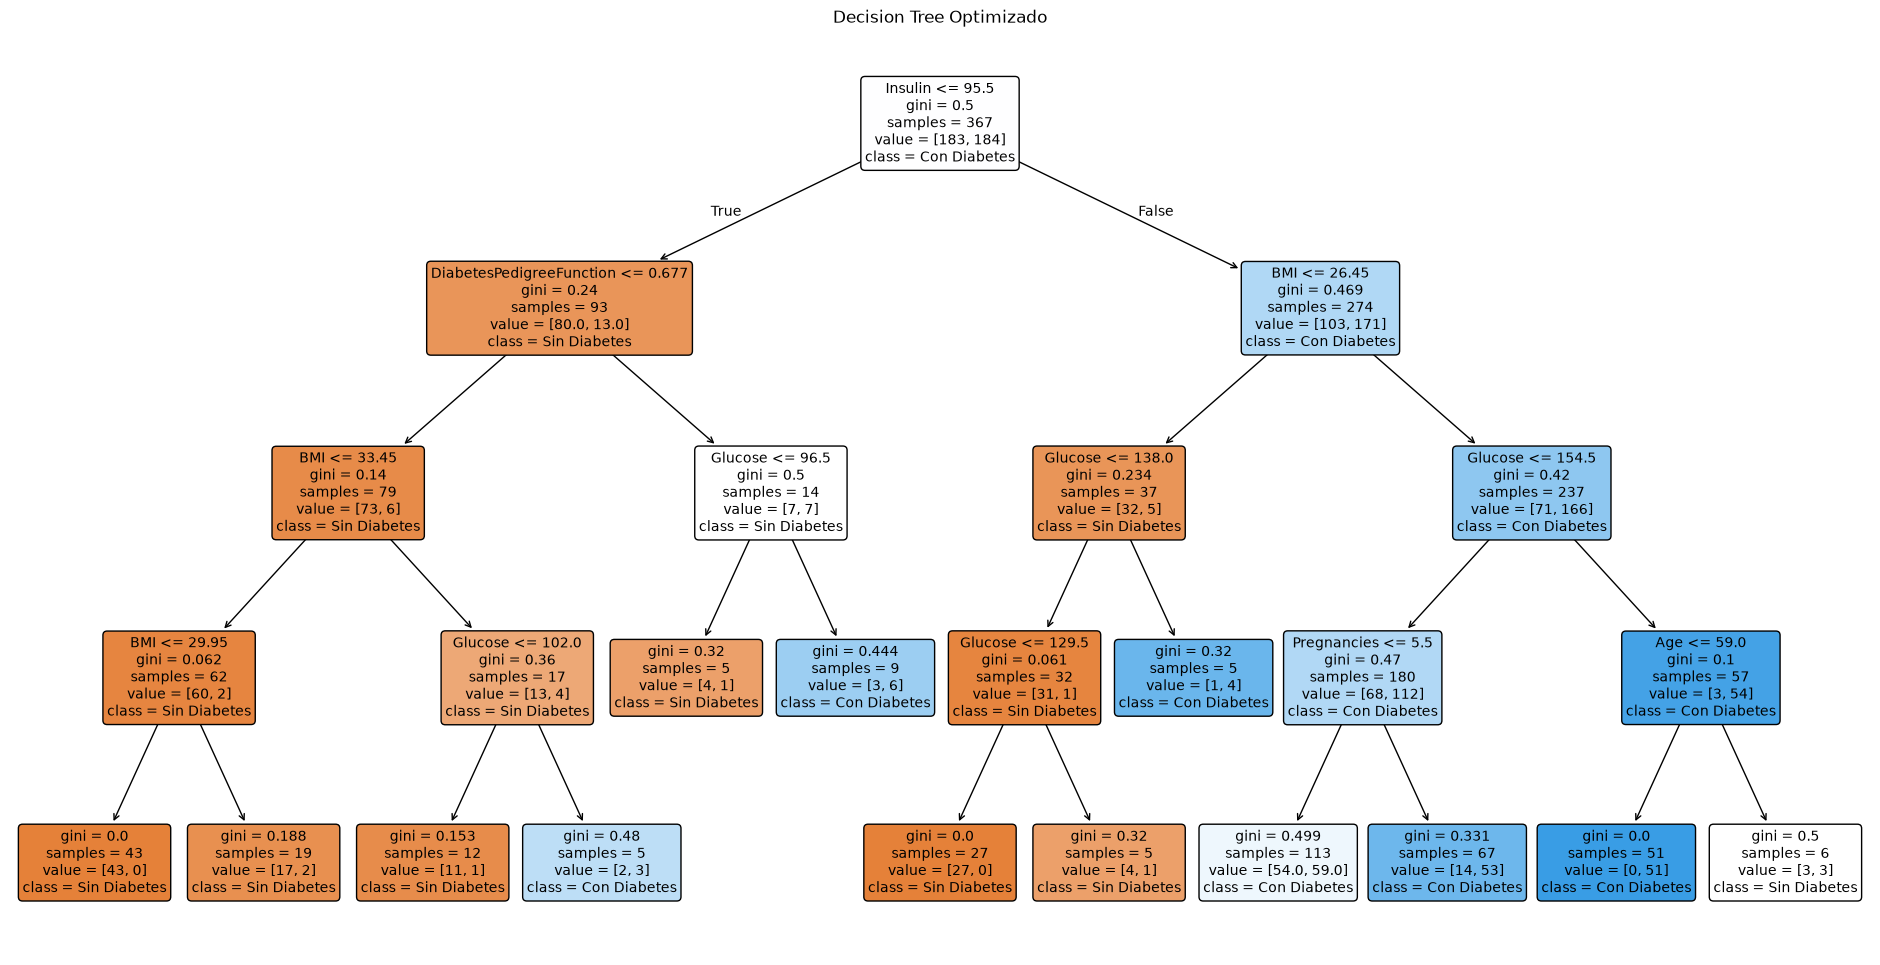

In [10]:
# ENTRENAMIENTO DE DECISION TREE

# Definimos los dataframes para los features y los targets
dfFeatures = df.drop('Outcome', axis=1)
dfTargets = df['Outcome']

# Partimos el conjunto de datos de entrenamiento y de prueba manteniendo la proporción de clases
x_train, x_test, y_train, y_test = train_test_split(
    dfFeatures, dfTargets, test_size=0.25, random_state=42, stratify=dfTargets
)

# Creamos el modelo optimizado para evitar sobreajuste y lo entrenamos
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)
model.fit(x_train, y_train)

# Evaluamos el score en entrenamiento y prueba
train_accuracy = model.score(x_train, y_train)
y_pred = model.predict(x_test)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy en entrenamiento: {train_accuracy:.2f}")
print(f"Accuracy en prueba: {test_accuracy:.2f}\n")

# Generamos una prediccion y con ella generamos un reporte de clasificacion
report = classification_report(y_test, y_pred)
print(report)

# Mostramos el plot del arbol graficado
plt.figure(figsize=(24, 12))
plot_tree(
    model,
    filled=True,
    rounded=True,
    feature_names=dfFeatures.columns,
    class_names=['Sin Diabetes', 'Con Diabetes'],
    fontsize=10
)
plt.title('Decision Tree Optimizado')
plt.savefig('decision_tree.png', bbox_inches='tight')
plt.show()